# WICOS: data exploration and data split
This notebook looks at the raw DopNet spectrograms and explains how the data is split into training, validation and test data.

The data is loaded and split with `load_data` and `split` from `src/prepare_data.py`: the same code that builds the model-ready dataset (`data/processed/wicos_dataset.npz`). The pre-processing is explained in `preprocessing.ipynb`, the hand-crafted features in `features.ipynb`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("../src").resolve()))
from prepare_data import GESTURES, OUT_DIR, load_data, split

# Folder for report figures
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(exist_ok=True)

# Load data
`load_data` reads every CSV file `data/Person */<gesture>/Person?g?s*.csv` (sorted, so the sample order does not depend on the file system). It returns:

- `spectrograms`: a list of 960 arrays, one per sample. Rows are Doppler bins, columns are time bins, values are magnitudes in dB.
- `metadata`: a DataFrame with one row per sample (person, gesture label, gesture name, sample number), aligned with `spectrograms`.

In [2]:
spectrograms, metadata = load_data()
print(f"Loaded {len(spectrograms)} spectrograms")
display(metadata.groupby(["person", "gesture"]).size().unstack()[GESTURES])

Loaded 960 spectrograms


gesture,wave,pinch,swipe,click
person,,,,
A,40,40,40,40
B,40,40,40,40
C,40,40,40,40
D,40,40,40,40
E,40,40,40,40
F,40,40,40,40


# Data exploration
### Missing and empty values

In [3]:
# Missing (NaN), infinite and empty (constant) samples
n_nan = sum(np.isnan(x).any() for x in spectrograms)
n_inf = sum(np.isinf(x).any() for x in spectrograms)
n_constant = sum(x.min() == x.max() for x in spectrograms)

print(f"Samples with NaN:      {n_nan}")
print(f"Samples with inf:      {n_inf}")
print(f"Constant samples:      {n_constant}")

Samples with NaN:      0
Samples with inf:      0
Constant samples:      0


### Data shape

In [4]:
n_doppler = np.unique([x.shape[0] for x in spectrograms])
n_time = np.array([x.shape[1] for x in spectrograms])

print(f"Doppler bins (rows):  {n_doppler}")
print(f"Time bins (columns):  min {n_time.min()}, max {n_time.max()}")
print(f"Value range [dB]:     min {min(x.min() for x in spectrograms):.1f}, max {max(x.max() for x in spectrograms):.1f}")
print(f"Maximum per sample:   {np.unique([x.max() for x in spectrograms])} dB")
print(f"Example sample:       shape {spectrograms[0].shape} -> {metadata.iloc[0].to_dict()}")

Doppler bins (rows):  [800]
Time bins (columns):  min 43, max 448


Value range [dB]:     min -121.3, max 0.0
Maximum per sample:   [0.] dB
Example sample:       shape (800, 92) -> {'person': 'A', 'label': 3, 'gesture': 'click', 'sample': 1}


**Interpretation:**
- Every spectrogram has the same 800 Doppler bins; zero Doppler (no motion) is the centre, bin 400.
- The number of time bins varies between 43 and 448, depending on the sample and the gesture.
- Every sample is normalised to its own maximum: the peak is exactly 0 dB in every sample.

### Example plots

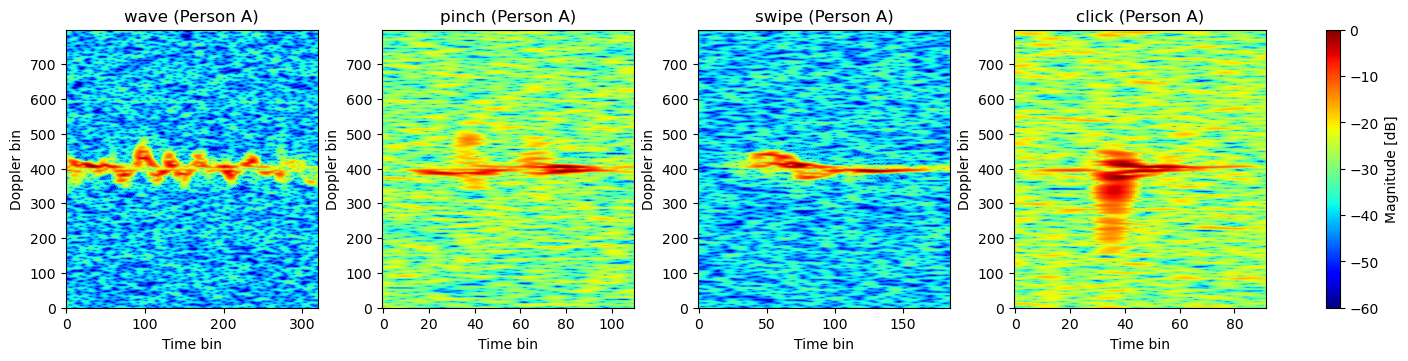

In [5]:
# The first sample of each gesture
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), constrained_layout=True)
for ax, g in zip(axes, GESTURES):
    i = metadata.index[metadata.gesture == g][0]
    im = ax.imshow(spectrograms[i], aspect="auto", origin="lower", cmap="jet", vmin=-60, vmax=0)
    ax.set_title(f"{g} (Person {metadata.person[i]})")
    ax.set_xlabel("Time bin")
    ax.set_ylabel("Doppler bin")
fig.colorbar(im, ax=axes, label="Magnitude [dB]")
fig.savefig(FIG_DIR / "spectrograms.pdf", bbox_inches="tight")
plt.show()

### Sample lengths
The recordings have different lengths. The histogram shows the number of time bins per sample, stacked per gesture; the tables show the median length per gesture and per person.

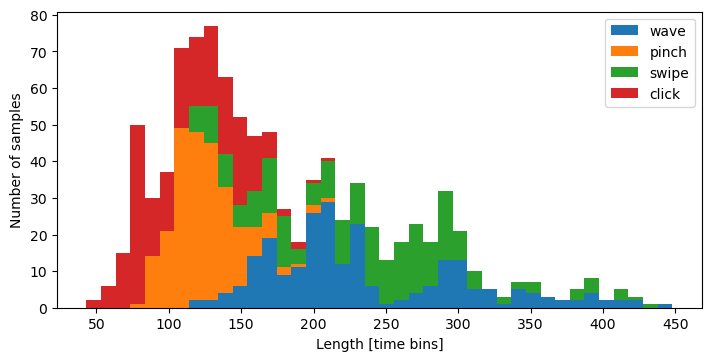

gesture,wave,pinch,swipe,click
person,,,,
A,356.0,139.5,275.0,113.0
B,162.5,122.0,280.5,149.5
C,199.0,121.0,271.0,85.5
D,227.0,128.0,241.0,141.0
E,295.0,108.0,170.0,107.0
F,202.0,105.0,164.0,78.0


In [6]:
lengths = metadata.assign(length=n_time)

fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.hist([lengths.length[lengths.gesture == g] for g in GESTURES], bins=40, stacked=True, label=GESTURES)
ax.set_xlabel("Length [time bins]")
ax.set_ylabel("Number of samples")
ax.legend()
fig.savefig(FIG_DIR / "length_histogram.pdf", bbox_inches="tight")
plt.show()

display(lengths.pivot_table(index="person", columns="gesture", values="length", aggfunc="median")[GESTURES])

**Interpretation:**
- The length depends strongly on the gesture: wave and swipe are long movements (median about 160-360 time bins), pinch and click short ones (about 80-150).
- The length also depends on the person: Person A's waves (356) take more than twice as long as Person B's (163), and Persons E and F are shorter overall.
- So the length carries information about the gesture, but also about the person. The images are resized to a fixed 128 time bins, which removes it; the hand-crafted features keep it as `duration` (see `features.ipynb`).

### Magnitude values
Distribution of all magnitude values (all time-Doppler bins of all samples), per gesture. Most bins contain only background noise; the gesture is the thin tail towards 0 dB.

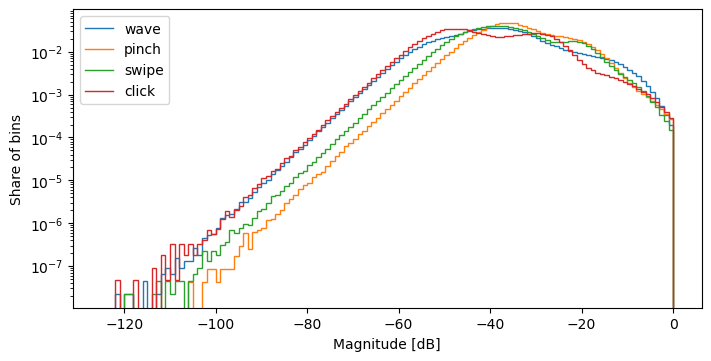

In [7]:
# Histogram per gesture, accumulated sample by sample (all pixels together do not fit in memory comfortably)
edges = np.arange(-125, 1, 1.0)
counts = {g: np.zeros(len(edges) - 1) for g in GESTURES}
for x, g in zip(spectrograms, metadata.gesture):
    counts[g] += np.histogram(x, bins=edges)[0]

fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
for g in GESTURES:
    ax.stairs(counts[g] / counts[g].sum(), edges, label=g)
ax.set_yscale("log")
ax.set_xlabel("Magnitude [dB]")
ax.set_ylabel("Share of bins")
ax.legend()
fig.savefig(FIG_DIR / "magnitude_histogram.pdf", bbox_inches="tight")
plt.show()

**Interpretation:**
- The distributions are broad (from about -120 to 0 dB) and peak around -40 dB: the background noise, which fills most of the bins.
- The gesture is the shoulder from about -20 to 0 dB. It holds only a small share of the bins, which is why the pre-processing removes the noise and crops the Doppler axis.
- The gestures hardly differ in their magnitude distribution: what separates them is *where* in time and Doppler the energy is, not how strong it is.

### Differences between persons
The background noise level (median of all bins of a sample, see `preprocessing.ipynb`) and the sample length per person. Large differences between persons are what makes a new, unseen person hard for the models.

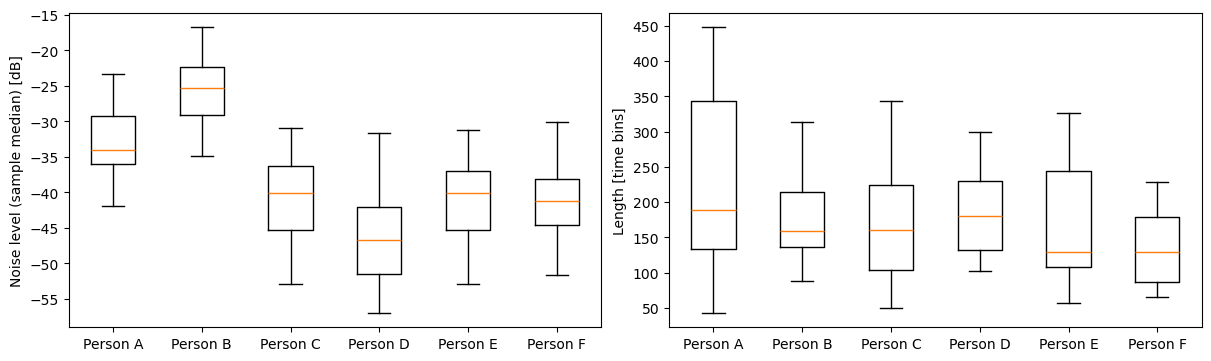

person,A,B,C,D,E,F
noise_level,-34.0,-25.3,-40.1,-46.7,-40.1,-41.2
length,189.0,158.5,160.0,180.5,129.5,129.5


In [8]:
per_sample = metadata.assign(noise_level=[np.median(x) for x in spectrograms], length=n_time)
persons = sorted(per_sample.person.unique())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
for ax, (col, label) in zip(axes, [("noise_level", "Noise level (sample median) [dB]"), ("length", "Length [time bins]")]):
    ax.boxplot([per_sample[col][per_sample.person == p] for p in persons], showfliers=False)
    ax.set_xticks(range(1, len(persons) + 1), [f"Person {p}" for p in persons])
    ax.set_ylabel(label)
fig.savefig(FIG_DIR / "person_variability.pdf", bbox_inches="tight")
plt.show()

display(per_sample.groupby("person")[["noise_level", "length"]].median().round(1).T)

**Interpretation:**
- The background noise level differs a lot between persons: Person B's recordings are about 15-20 dB noisier than those of Persons C-F (median -25 dB vs -40 to -47 dB), and it also varies within one person. A fixed dB threshold can therefore not separate gesture from noise for all samples; `preprocessing.ipynb` uses a noise floor per sample instead.
- The lengths overlap strongly between persons, but Persons E and F make shorter recordings than A and D.

# Data split
The dataset is split into three roles: training, validation and test.

- The **test set (20%)** is separated first, before any (pre-)processing choice is made. This prevents data leakage from the test set into the training data. The test set is only used at the very end to evaluate the final model. The split is stratified on person and gesture, so every person-gesture combination has the same share in the test set.
- The **training set (80%)** contains the remaining data. Every choice that is learned from data (the noise margin and Doppler crop in `preprocessing.ipynb`, the feature checks in `features.ipynb`, the model and its hyperparameters) uses the training set only.
- **Validation** is done with stratified **5-fold cross-validation** on the training set. The training set is split into 5 folds, stratified on person and gesture (like the test split), so every fold has the same share of each person-gesture combination. The persons differ a lot (see above), so this keeps the folds comparable and the fold-to-fold spread of the score honest. A model is trained on 4 folds and evaluated on the 5th; this is repeated so that every fold is the validation fold once. The model and hyperparameters are chosen on the mean validation score over the folds. No data is lost to validation, and the estimate is more reliable than with a single small validation set.

After choosing the model and hyperparameters, the model is retrained on the entire training set. This retraining uses the data that was first used for validation (which influenced the model choice), so the model is finally evaluated on the test set that was set aside at the very beginning: data the model has never seen.

It is also interesting to see how well a model generalises to **new persons**. Therefore a second validation leaves one person out per fold (**leave-one-subject-out, LOSO**). There are 6 persons (A to F), so there are 6 folds.

So:
1. Separate a 20% test set.
2. Choose the model and hyperparameters with 5-fold cross-validation.
3. Evaluate the chosen model with 6-fold LOSO, to see how it generalises to a new person.
4. Retrain the chosen model on all training data. This is the final model.
5. Evaluate the final model once on the test set from the beginning.

**Implementation.** `split` in `src/prepare_data.py` makes the test split and the 5 CV folds; they are saved in the dataset as `idx_train`, `idx_test` and `cv_fold` (0-4 for training samples, -1 for test samples). The LOSO folds follow directly from the saved `persons`, so the model notebooks make them with `LeaveOneGroupOut`.

In [9]:
idx_train, idx_test, cv_fold = split(metadata)
print(f"Train: {len(idx_train)}, test: {len(idx_test)}, CV folds: {len(np.unique(cv_fold[idx_train]))}, "
      f"LOSO folds: {metadata.person.nunique()}")

# The stratification worked: every gesture (and person) has the same share in each set and each fold
role = np.where(cv_fold < 0, "test", "fold " + cv_fold.astype(str))
display(metadata.groupby([role, "gesture"]).size().unstack()[GESTURES])
display(metadata.groupby([role, "person"]).size().unstack())

Train: 768, test: 192, CV folds: 5, LOSO folds: 6


gesture,wave,pinch,swipe,click
fold 0,41,38,37,38
fold 1,39,38,40,37
fold 2,37,38,40,39
fold 3,37,39,38,39
fold 4,38,39,37,39
test,48,48,48,48


person,A,B,C,D,E,F
fold 0,25,26,26,24,26,27
fold 1,24,26,26,25,25,28
fold 2,26,25,25,28,25,25
fold 3,27,25,25,27,25,24
fold 4,26,26,26,24,27,24
test,32,32,32,32,32,32


In [10]:
# Check: the saved dataset uses exactly this split
data = np.load(OUT_DIR / "wicos_dataset.npz")
print("Same split as wicos_dataset.npz:", all(np.array_equal(a, data[k]) for a, k in
      [(idx_train, "idx_train"), (idx_test, "idx_test"), (cv_fold, "cv_fold")]))

Same split as wicos_dataset.npz: True
